<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<h1><center><font size=10>Artificial Intelligence and Machine Learning</center></font></h1>



<center> <font size=6> Project Python Foundations: FoodHub Data Analysis

<center><img src="https://www.netsolutions.com/wp-content/uploads/2022/10/essential-features-of-building-an-on-demand-food-ordering-app.jpg" width="720"></center>


### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [1]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Read the data
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks'
    + '/UT Austin AI ML Program'
    + '/Project Python Foundations - FoodHub Data Analysis'
    + '/foodhub_order.csv'
)


In [5]:
# Return the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [6]:
# Check dataset's shape of rows and columns
rows, columns = df.shape
print(f'The FoodHub dataset has {rows} rows and {columns} columns.')

The FoodHub dataset has 1898 rows and 9 columns.


#### Observations:

The FoodHub dataset has 1 header row, 1898 data rows, and 9 columns.


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [7]:
# Show what datatypes pandas has defaulted to for each column of the dataset
# when it read the CSV
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:

There are three main types of data: int64, object, and float64. Although "rating" is mostly an integer, there are numerous rows of rating "Not given" in the dataset, making it an object. This may need to be sanitized.


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [8]:
# Check for null/missing values in the dataset
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations: As the sum of null values per column shows as 0 for all columns, there are no missing values in the dataset.


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [9]:
# Choose column 'food_preparation_time'
food_prep_time = df['food_preparation_time']

# Show pandas statistical summary of the food preparation time
prep_time_summary = food_prep_time.describe()
print(f"Statistical summary [food_preparation_time]:\n{prep_time_summary}\n")

# Likewise, we can use the following functions to calculate the minimum, mean,
# and maximum time for food preparation time
min_prep_time = food_prep_time.min()
avg_prep_time = food_prep_time.mean()
max_prep_time = food_prep_time.max()
print(f"Minimum Food Prep Time:\t{min_prep_time}")
print(f"Mean Food Prep Time:\t{avg_prep_time}")
print(f"Maximum Food Prep Time:\t{max_prep_time}")

Statistical summary [food_preparation_time]:
count    1898.000000
mean       27.371970
std         4.632481
min        20.000000
25%        23.000000
50%        27.000000
75%        31.000000
max        35.000000
Name: food_preparation_time, dtype: float64

Minimum Food Prep Time:	20
Mean Food Prep Time:	27.371970495258168
Maximum Food Prep Time:	35


#### Observations:

A FoodHub-participating restaurant takes a certain amount of time to prepare food once an order has been place. This is identified by the "food_preparation_time" column.

The minimum time it takes is 20 minutes.

On average, it takes about 27.37 minutes.

The maximum time it takes is 35 minutes.


### **Question 5:** How many orders are not rated? [1 mark]

In [10]:
# Show all unique values in "rating" column and their counts
rating_uniques = df['rating'].value_counts()
print(rating_uniques, '\n')

# # Replacing "Not given" with NA makes it recognizable as a missing value
# df['rating'] = df['rating'].replace('Not given', pd.NA)

# # Convert rating column to float
# df['rating'] = df['rating'].astype(float)

# rating_uniques = df['rating'].value_counts(dropna=False)
# print(rating_uniques, '\n')

# Find ratings marked as NA
unrated_count = (df['rating'] == 'Not given').sum()
print(f'There are {unrated_count} orders with no rating.')

rating
Not given    736
5            588
4            386
3            188
Name: count, dtype: int64 

There are 736 orders with no rating.


#### Observations:

There are 736 accounts of "Not given" ratings across all rows in this dataset. The rest are rated 3, 4, or 5.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

# order_id

In [11]:
# Show all unique values in "order_id" column and their counts
order_id_uniques = df['order_id'].value_counts()
print(order_id_uniques, '\n')

# Similarly, we can use the following method
order_id_uniques = df['order_id'].nunique()
print(f'There are {order_id_uniques} unique order IDs.')

order_id
1478056    1
1477147    1
1477685    1
1477070    1
1477334    1
          ..
1478198    1
1477449    1
1476966    1
1478437    1
1477895    1
Name: count, Length: 1898, dtype: int64 

There are 1898 unique order IDs.


The "order_id" column contains 1898 unique values, which is equivalent to our data rows. This means that "order_id" is unique, and therefore there is not much to explore here.

# customer_id


Synopsis: The analysis of customer ID reveals a highly skewed pattern, indicating that most customers place only one or two orders. A small number of customers contribute disproportionately to total orders, suggesting the presence of high-value repeat users.

In [12]:
# Show statistical analysis on "customer_id"
orders_per_customer = df['customer_id'].value_counts()
print(orders_per_customer.describe(), '\n')

# Count number of orders per customer
top_customers = (
    df['customer_id']
    .value_counts()   # count occurrences
    .head(10)         # top 10
    .reset_index()    # convert to DataFrame
)

# Rename columns for clarity
top_customers.columns = ['customer_id', 'order_count']
print(top_customers, '\n')

count    1200.000000
mean        1.581667
std         1.090560
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        13.000000
Name: count, dtype: float64 

   customer_id  order_count
0        52832           13
1        47440           10
2        83287            9
3       250494            8
4       259341            7
5        65009            7
6       276192            7
7        82041            7
8       115213            6
9        60052            6 



Out of 1898 data rows there are 1200 unique customer_id's, meaning there are customers who have ordered more than one time.

The least amount of orders placed by a customer is 1.

The average amount of orders placed by a customer is about 1.58.

The greatest amount of orders placed by a customer is 13.

The customer with ID 52832 placed the most number of orders, at 13 orders.

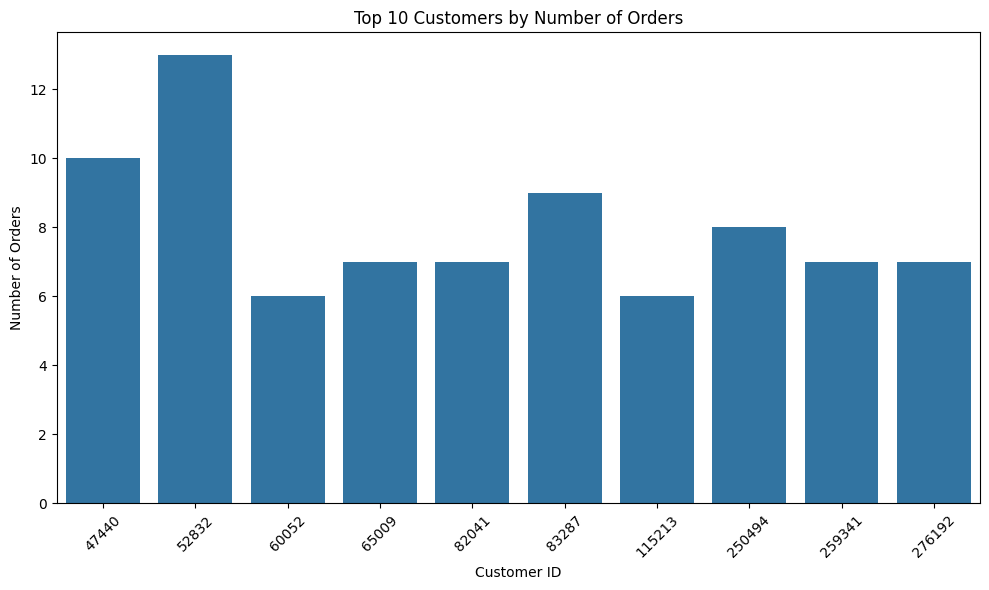

In [13]:
# Plot showing the top 10 customers who ordered the most
plt.figure(figsize=(10, 6))
sns.barplot(data=top_customers, x='customer_id', y='order_count')
plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Customer ID')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

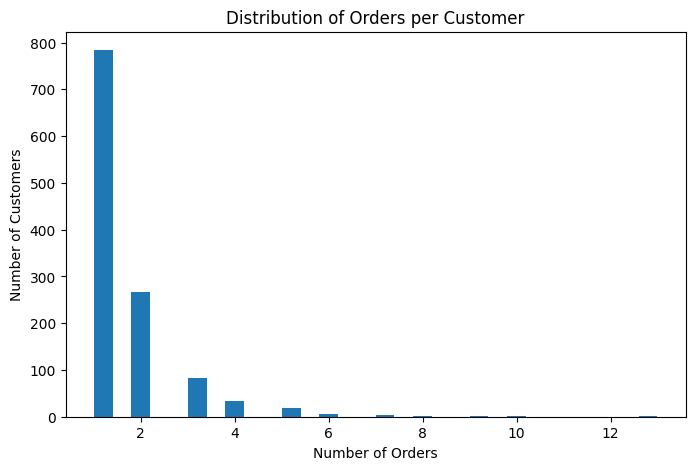

In [14]:
# Plot showing the distribution of order amounts per customer
plt.figure(figsize=(8, 5))
plt.hist(orders_per_customer, bins=30)
plt.title('Distribution of Orders per Customer')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')
plt.show()

The above plot shows that the distribution of orders per customer is highly right-skewed, indicating that most customers place only one or two orders. Almost 800 customers made one order only.

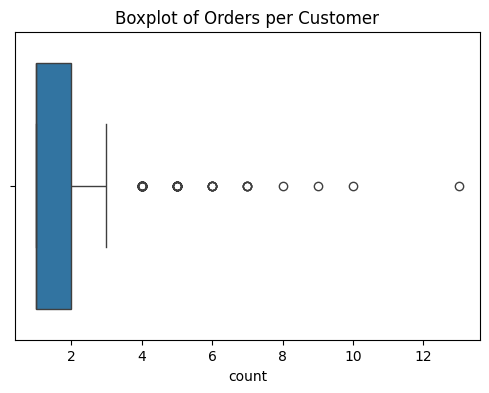

In [15]:
# Plot to show outliers
plt.figure(figsize=(6, 4))
sns.boxplot(x=orders_per_customer)
plt.title('Boxplot of Orders per Customer')
plt.show()

The above boxplot shows that there are many outliers of customers and their amounts of orders.

In [16]:
# Check amount of orderers who ordered once and more than once
one_time = (orders_per_customer == 1).sum()
repeat = (orders_per_customer > 1).sum()

print("One-time orderers %:", one_time / len(orders_per_customer))
print("Repeat orderers %:", repeat / len(orders_per_customer))

One-time orderers %: 0.6533333333333333
Repeat orderers %: 0.3466666666666667


The above code can detail retention versus churn behavior, showing that around 65% of orders are one-time orders and 35% are repeat orders. This may indicate low retention.

In [17]:
# Check the contribution of orders from the top 10 orderers
top_10 = orders_per_customer.head(10).sum()
total_orders = orders_per_customer.sum()

print("Top 10 contribution:", top_10 / total_orders)

Top 10 contribution: 0.04214963119072708


The Pareto analysis, also known as the 80/20 rule, states that approximately 80% of effects come from 20% of causes.

We can see in the above code that the top 10 most ordering customers account for only about 4.21% of all orders.

# restaurant_name

Synopsis: The analysis of restaurant order distribution reveals a highly skewed pattern, where a small number of restaurants dominate total order volume while the majority receive relatively few orders. This indicates a strong preference concentration among customers and suggests the presence of high-performing vendors alongside a long tail of underutilized restaurants.

In [18]:
# Check amount of unique restaurants
print(df['restaurant_name'].nunique())

178


The dataset contains 178 unique restaurants, indicating the platform supports a moderate variety of vendors.

In [19]:
# Check number of unique entries of restaurant
orders_per_restaurant = df['restaurant_name'].value_counts()

# Get the top 10
top_10_restaurants = orders_per_restaurant.head(10)
print(top_10_restaurants)

restaurant_name
Shake Shack                      219
The Meatball Shop                132
Blue Ribbon Sushi                119
Blue Ribbon Fried Chicken         96
Parm                              68
RedFarm Broadway                  59
RedFarm Hudson                    55
TAO                               49
Han Dynasty                       46
Blue Ribbon Sushi Bar & Grill     44
Name: count, dtype: int64


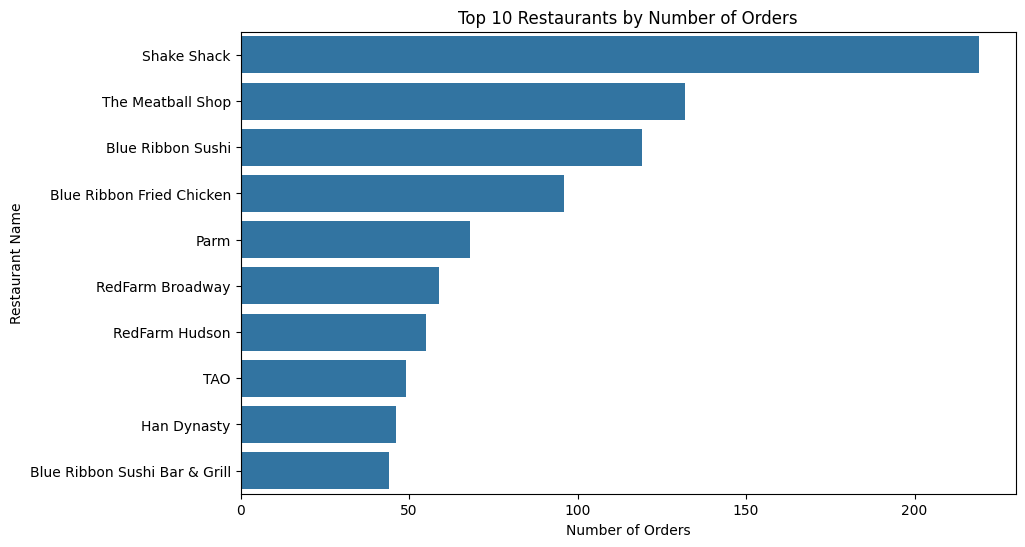

In [20]:
# Plot the top 10 restaurants by their number of orders
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_restaurants.values, y=top_10_restaurants.index)
plt.title('Top 10 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.show()

The above plot shows that a small number of restaurants dominate the order volume, with the top restaurant receiving 219 orders.

This suggests that customer demand is concentrated among a few popular restaurants, including Shake Shack, The Meatball Shop, and Blue Ribbon Sushi to name the top few.

There is a steep drop-off after the top few restaurants, indicating a long-tail distribution.

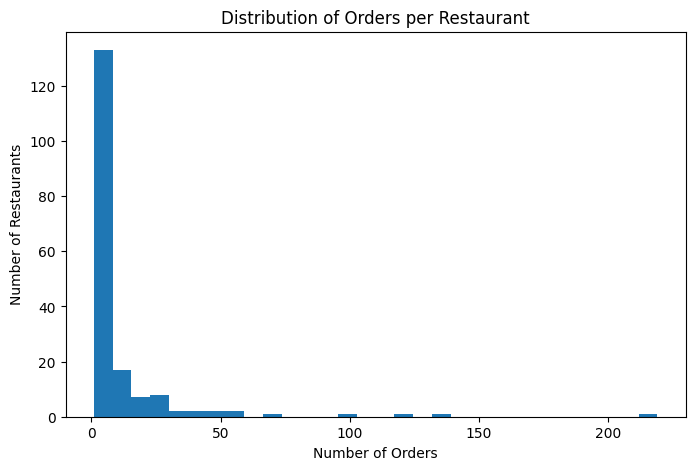

In [21]:
# Plot the distribution of number of orders across the restaurants
plt.figure(figsize=(8, 5))
plt.hist(orders_per_restaurant, bins=30)
plt.title('Distribution of Orders per Restaurant')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Restaurants')
plt.show()

The above plot shows that the distribution of orders per restaurant is right-skewed, indicating that most restaurants receive relatively few orders.

Only a small number of restaurants receive a high volume of orders, typical of marketplace platforms where a few vendors dominate demand.

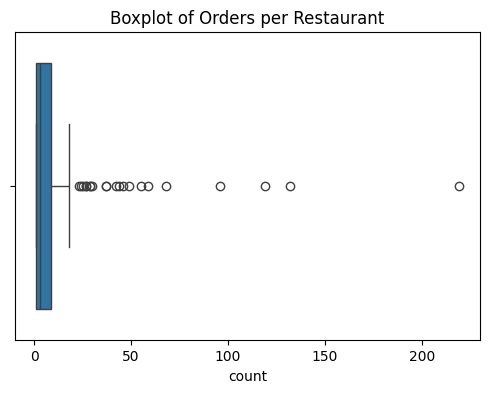

In [22]:
# Plot to show outliers
plt.figure(figsize=(6, 4))
sns.boxplot(x=orders_per_restaurant)
plt.title('Boxplot of Orders per Restaurant')
plt.show()

The above boxplot reveals several high-value outliers, representing restaurants with exceptionally high order volumes.

The majority of restaurants fall within a narrow range of low order counts, further confirming the presence of a long-tail distribution.

In [23]:
# Check on restaurants with single or low amount of orders
single_order_restaurants = (orders_per_restaurant == 1).sum()
low_order_restaurants = (orders_per_restaurant <= 3).sum()
total_restaurants = len(orders_per_restaurant)

print("Single-order restaurant %:", single_order_restaurants / total_restaurants)
print("Low-order restaurant %:", low_order_restaurants / total_restaurants)

Single-order restaurant %: 0.2808988764044944
Low-order restaurant %: 0.5393258426966292


About 28% of restaurants received only one order.

A resounding 54% of restaurants received only 3 or fewer orders.

This may indicate that a large portion of restaurants have minimal engagement, suggesting potential issues with visibility, marketing, or customer preference.

In [24]:
# Check the contribution of orders from the top 10 restaurants
top_10_total = orders_per_restaurant.head(10).sum()
total_orders = orders_per_restaurant.sum()

print("Top 10 contribution:", top_10_total / total_orders)

Top 10 contribution: 0.4673340358271865


The above code shows that the top 10 restaurants account for approximately 47% of total orders, highlighting a strong concentration of demand within these top 10 restaurants.

This may indicate a heavy reliance on a small number of restaurants for overall FoodHub platform activity.

# cuisine_type

Synopsis: The analysis of cuisine types reveals that customer preferences are highly concentrated among a few popular cuisines, while the majority of cuisine types receive relatively low order volumes. This indicates a skewed distribution with a strong preference for specific food categories. The presence of many low-frequency cuisines suggests a long-tail market, where niche options exist but contribute minimally to overall demand.

I like tacos.

In [25]:
# Check amount of unique cuisines
print(df['cuisine_type'].nunique())

14


The dataset contains 14 unique cuisine types, indicating the FoodHub platform supports a moderate variety of cuisines.

In [26]:
# Check amount ordered of each unique cuisine type
cuisine_counts = df['cuisine_type'].value_counts()
print(cuisine_counts)

cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Southern           17
Korean             13
Spanish            12
Vietnamese          7
Name: count, dtype: int64


The above code shows that the most ordered cuisine type on the FoodHub platform is American.

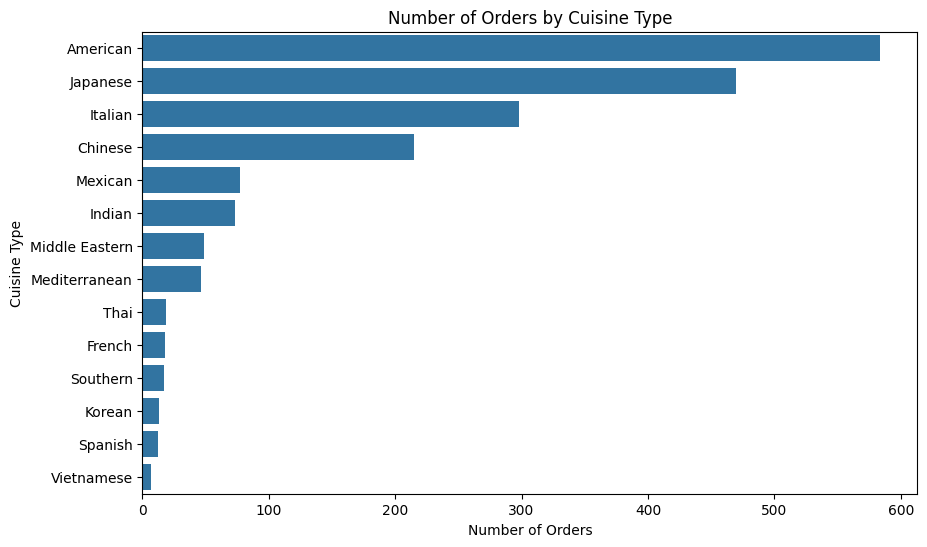

In [27]:
# Plot the number of orders by cuisine type
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='cuisine_type', order=cuisine_counts.index)
plt.title('Number of Orders by Cuisine Type')
plt.xlabel('Number of Orders')
plt.ylabel('Cuisine Type')
plt.show()

The above countplot shows that there is a noticeable drop-off in order frequency among less popular cuisines.

This suggests that customer demand is concentrated around a few preferred cuisine categories, namely American, Japanese, Italian, and Chinese.

In [28]:
# Calculate cuisine preference percentage
cuisine_percent = df['cuisine_type'].value_counts(normalize=True) * 100
print(cuisine_percent)

cuisine_type
American          30.769231
Japanese          24.762908
Italian           15.700738
Chinese           11.327713
Mexican            4.056902
Indian             3.846154
Middle Eastern     2.581665
Mediterranean      2.423604
Thai               1.001054
French             0.948367
Southern           0.895680
Korean             0.684932
Spanish            0.632244
Vietnamese         0.368809
Name: proportion, dtype: float64


The most popular cuisine, American, accounts for approximately 31% of total orders, indicating a strong preference for this cuisine.

Lower-ranked cuisines contribute only a small fraction individually, reflecting niche demand and highlighting an imbalance in cuisine popularity.

In [29]:
# Calculate percentage of orders for which the cuisine count is 50 or less
rarer_cuisines = (cuisine_counts <= 50).sum()
total_cuisines = len(cuisine_counts)

print("Rare cuisine %:", rarer_cuisines / total_cuisines)

Rare cuisine %: 0.5714285714285714


The above code shows that about 57%, a majority, of cuisines have 50 or less orders. That is considerable in a dataset of 1898 orders.

These cuisines may lack visibility or cater to niche audiences.

This could represent an opportunity for targeted marketing, or may indicate low demand.

# cost_of_the_order

Synopsis: The distribution of order cost is positively skewed, with most orders concentrated in the lower price range and a small number of high-value outliers. The mean exceeds the median, reinforcing the presence of a right tail. While the majority of customers place moderate-costing orders, a small fraction contributes disproportionately higher cost values.

In [30]:
# Show the statistical analysis of order cost column
df['cost_of_the_order'].describe()

,cost_of_the_order
count,1898.000000
mean,16.498851
std,7.483812
min,4.470000
25%,12.080000
50%,14.140000
75%,22.297500
max,35.410000


Order costs range from 4.47 to 35.41 dollars, indicating a wide spread in spending behavior.

The average order cost is approximately 16.50 dollars. This is greater than the median of 14.14 dollars, indicating a right-skewed distribution driven by higher-value orders.


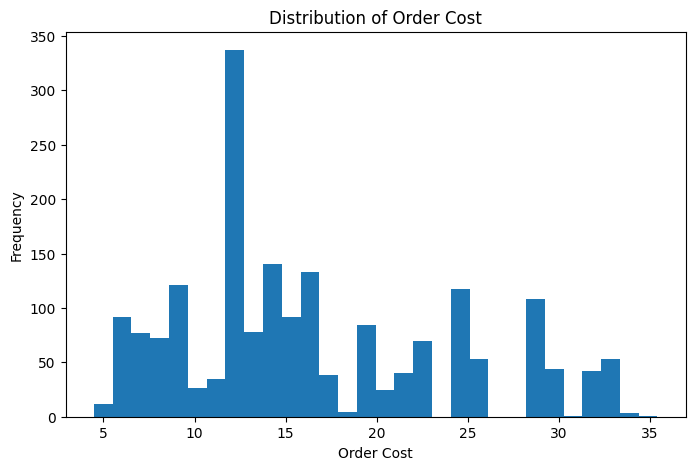

In [31]:
# Plot the distribution of order cost
plt.figure(figsize=(8, 5))
plt.hist(df['cost_of_the_order'], bins=30)
plt.title('Distribution of Order Cost')
plt.xlabel('Order Cost')
plt.ylabel('Frequency')
plt.show()

The above histogram show that the distribution of order costs appears right-skewed, with most orders concentrated in the lower price range.

There are relatively few high-value orders, forming a long tail on the right and suggesting that customers typically place lower-cost orders, with occasional larger purchases.

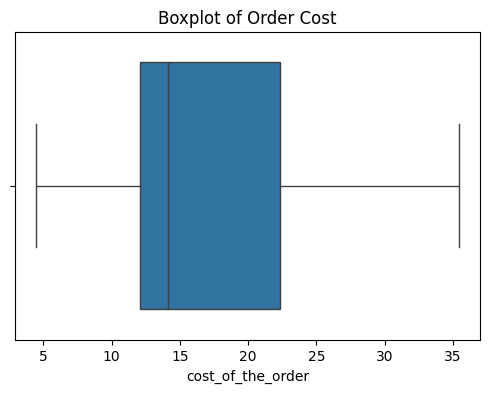

In [32]:
# Plot to show outliers
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['cost_of_the_order'])
plt.title('Boxplot of Order Cost')
plt.show()

The above boxplot shows outliers at the higher end of the cost spectrum.

Most orders fall within a relatively narrow interquartile range.

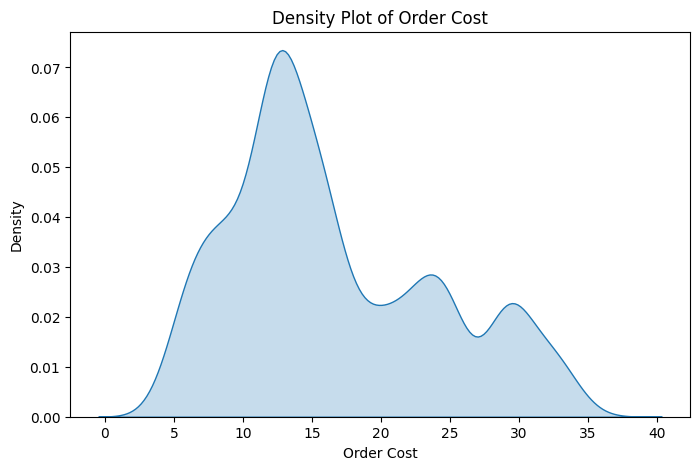

In [33]:
# Plot the density of order cost
plt.figure(figsize=(8, 5))
sns.kdeplot(df['cost_of_the_order'], fill=True)
plt.title('Density Plot of Order Cost')
plt.xlabel('Order Cost')
plt.show()

The density plot above confirms that order costs are concentrated around the 10 to 15 dollars range.

The smooth curve highlights a gradual decline in frequency as order cost increases, further reinforcing the presence of a right-skewed distribution.

In [34]:
# Calculate the skew of order cost
df['cost_of_the_order'].skew()

np.float64(0.6217469995871637)

The above code shows the skewness of the order cost, with a value of approximately 0.62, indicating a positive/right skew.

In [35]:
# Check the proportion of high-value orders
high_value = (df['cost_of_the_order'] > 30).sum()
total_orders = len(df)

print("High-value orders %:", high_value / total_orders)

High-value orders %: 0.05268703898840885


Approximately 5.27% of orders exceed 30 dollars, indicating that high-value purchases are relatively rare.

This suggests that most customers tend to place more moderate cost orders.

# day_of_the_week

Synopsis: Demand tends to increase on weekends, suggesting that external factors such as work schedules and leisure time influence ordering patterns. The observed variation highlights opportunities for targeted promotions and resource allocation based on day-specific demand.

In [36]:
# Sanity check unique values of day of week column
print(df['day_of_the_week'].unique())
print(df['day_of_the_week'].nunique())

['Weekend' 'Weekday']
2


In [37]:
# Check amount of orders per unique day of week
day_counts = df['day_of_the_week'].value_counts()
print(day_counts)

day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64


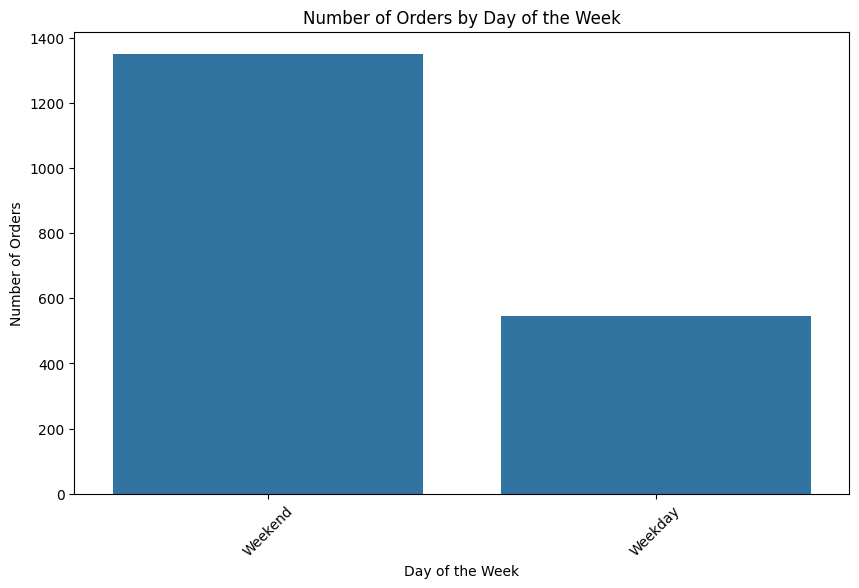

In [38]:
# Plot number of orders by day of week
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='day_of_the_week', order=day_counts.index)
plt.title('Number of Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

The above countplot shows that the majority of orders are placed on the weekend.

In [39]:
# Calculate the percentage of orders by day of week
day_percent = df['day_of_the_week'].value_counts(normalize=True) * 100
print(day_percent)

day_of_the_week
Weekend    71.18019
Weekday    28.81981
Name: proportion, dtype: float64


The above code shows that approximately 71% of orders are made on the weekend, compared to 29% on weekdays. This suggests increased leisure-time consumption.

# rating

Synopsis: The rating distribution is concentrated toward higher values, indicating strong overall customer satisfaction. Most ratings fall within the upper range (4 to 5). However, the presence of missing values suggests that not all customers provide feedback, which may introduce some bias. Overall, the data reflects a generally positive user experience with limited dissatisfaction.

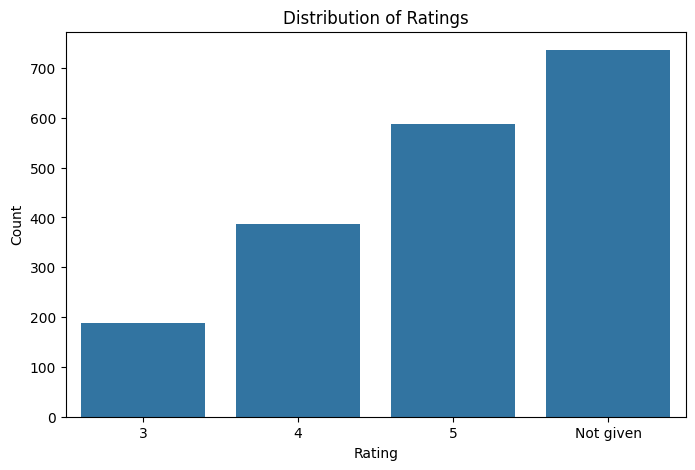

In [40]:
# Plot distribution of ratings
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='rating', order=sorted(df['rating']))
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

The above countplot shows that most orders are not rated. Ignoring unrated orders, a rating of 5 is the most frequent, indicating generally positive feedback.

In [41]:
# Calculate the percentages of different ratings
rating_percent = df['rating'].value_counts(normalize=True) * 100
print(rating_percent)

rating
Not given    38.777661
5            30.979979
4            20.337197
3             9.905163
Name: proportion, dtype: float64


Approximately 39% of all orders were not rated.

About 31% of customers extremely enjoyed their orders.

About 20% of customers moderately enjoyed their orders.

About 10% of customers should have gotten tacos.

# food_preparation_time

Synopsis: Food preparation time is generally concentrated within a typical range, indicating consistent kitchen performance for most orders.   Overall, preparation times appear stable but with room for improvement in handling high-delay cases.

In [42]:
# Statistical analysis of food prep time
df['food_preparation_time'].describe()

,food_preparation_time
count,1898.000000
mean,27.371970
std,4.632481
min,20.000000
25%,23.000000
50%,27.000000
75%,31.000000
max,35.000000


The preparation time ranges from 20 to 35 minutes, indicating moderately consistent kitchen performance.

The average food preparation time is approximately 27.37 minutes, with a median of 27 minutes. Although the average is slightly greater than the median, they are quite close, indicating relatively consistent preparation times across orders.





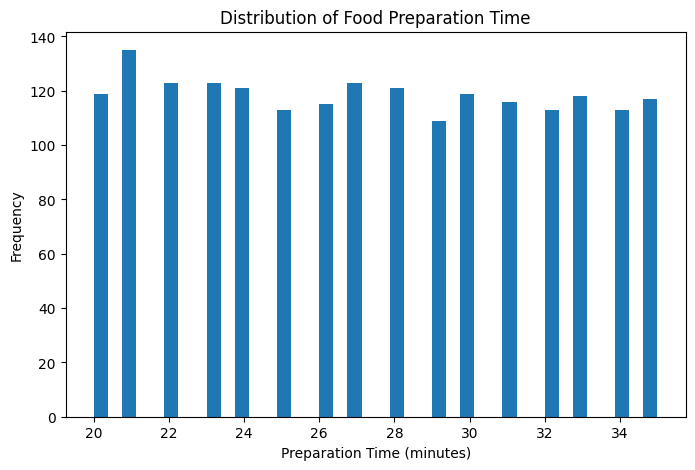

In [43]:
# Plot distribution of food prep times
plt.figure(figsize=(8, 5))
plt.hist(df['food_preparation_time'], bins=40)
plt.title('Distribution of Food Preparation Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Frequency')
plt.show()

The above histogram shows that the distribution appears symmetric.

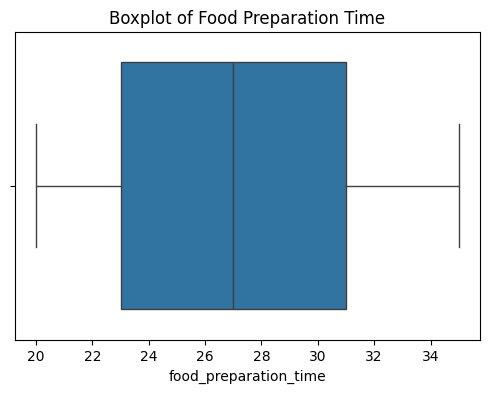

In [44]:
# Plot to show outliers and spread
plt.figure(figsize=(6,4))
sns.boxplot(x=df['food_preparation_time'])

plt.title('Boxplot of Food Preparation Time')
plt.show()

The above boxplot shows that the majority of orders fall within a relatively tight range, suggesting generally consistent kitchen performance.

Extreme values may represent peak-hour delays or operational inefficiencies.

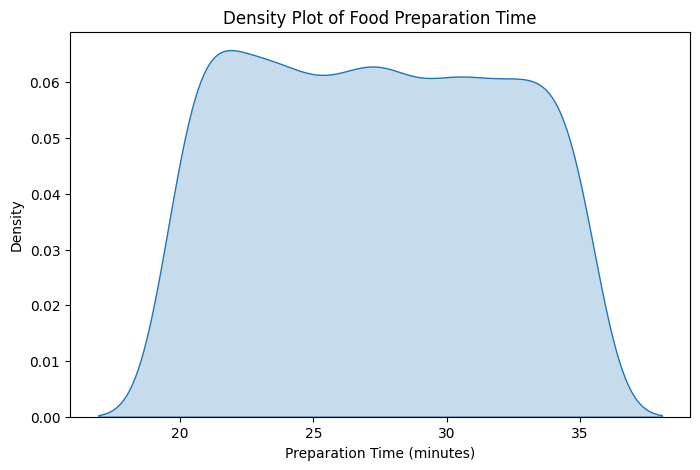

In [45]:
# Plot density of food prep time
plt.figure(figsize=(8, 5))
sns.kdeplot(df['food_preparation_time'], fill=True)
plt.title('Density Plot of Food Preparation Time')
plt.xlabel('Preparation Time (minutes)')
plt.show()

In [46]:
# Calculate the proportion of slowest orders
slow_orders = (df['food_preparation_time'] > 30).sum()
total_orders = len(df)

print("Slow orders %:", slow_orders / total_orders)

Slow orders %: 0.3040042149631191


The above code shows that almost one-third of all orders take greater than 30 minutes.

# delivery_time

Synopsis: Delivery time is generally concentrated within a typical range, indicating consistent logistics performance for most orders.

In [47]:
# Statistical analysis of delivery time
df['delivery_time'].describe()

,delivery_time
count,1898.000000
mean,24.161749
std,4.972637
min,15.000000
25%,20.000000
50%,25.000000
75%,28.000000
max,33.000000


Delivery time ranges from 15 minutes to 33 minutes.

It averages at approximately 24.16 minutes, which is close to the median of 25 minutes.

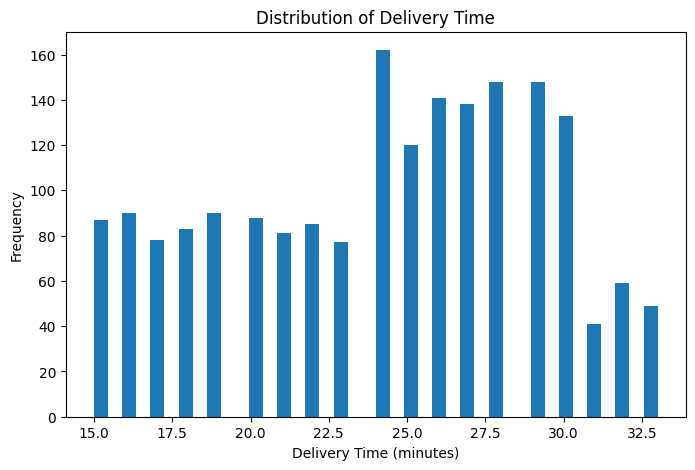

In [48]:
# Plot the distribution of delivery time
plt.figure(figsize=(8, 5))
plt.hist(df['delivery_time'], bins=40)
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Frequency')
plt.show()

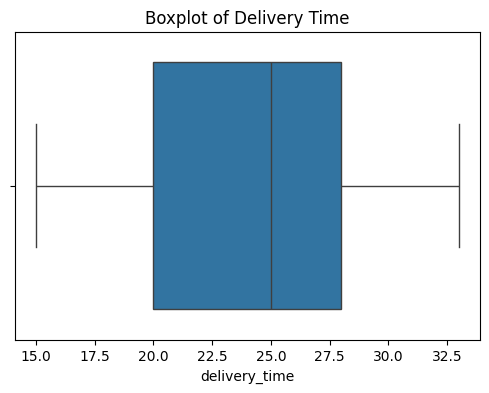

In [49]:
# Plot to show outliers and spread
plt.figure(figsize=(6,4))
sns.boxplot(x=df['delivery_time'])

plt.title('Boxplot of Delivery Time')
plt.show()

The above boxplot shows that deliveries fall within a relatively narrow interquartile range.

Extreme delivery times may be due to traffic, distance, or operational inefficiencies.

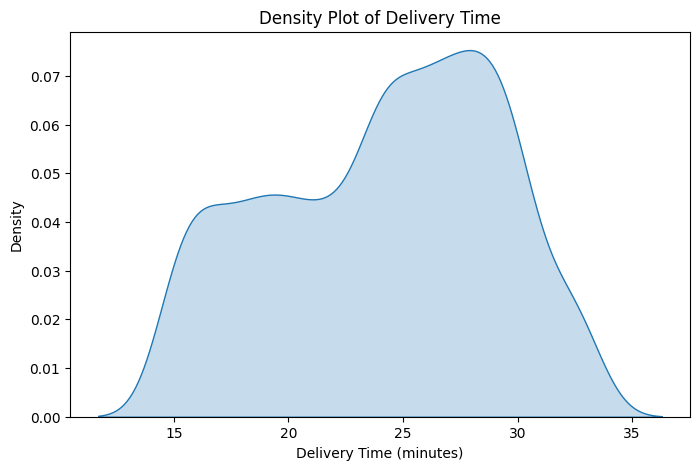

In [50]:
# Plot density of delivery time
plt.figure(figsize=(8, 5))
sns.kdeplot(df['delivery_time'], fill=True)
plt.title('Density Plot of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.show()

The above density plot shows that most orders take around 23 to 30 minutes to get delivered.

The gradual decline toward higher values indicates fewer delayed deliveries.

In [51]:
# Calculate percentage of most delayed orders greater than 30 minutes
delayed_orders = (df['delivery_time'] > 30).sum()
total_orders = len(df)

print("Delayed delivery %:", delayed_orders / total_orders)

Delayed delivery %: 0.07850368809272919


The above code shows that approximately 7.85% of orders take the longest to deliver.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [52]:
# Check number of unique entries of restaurant
orders_per_restaurant = df['restaurant_name'].value_counts()

# Get the top 5
top_5_restaurants = orders_per_restaurant.head(5)
print(top_5_restaurants)

restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
Name: count, dtype: int64


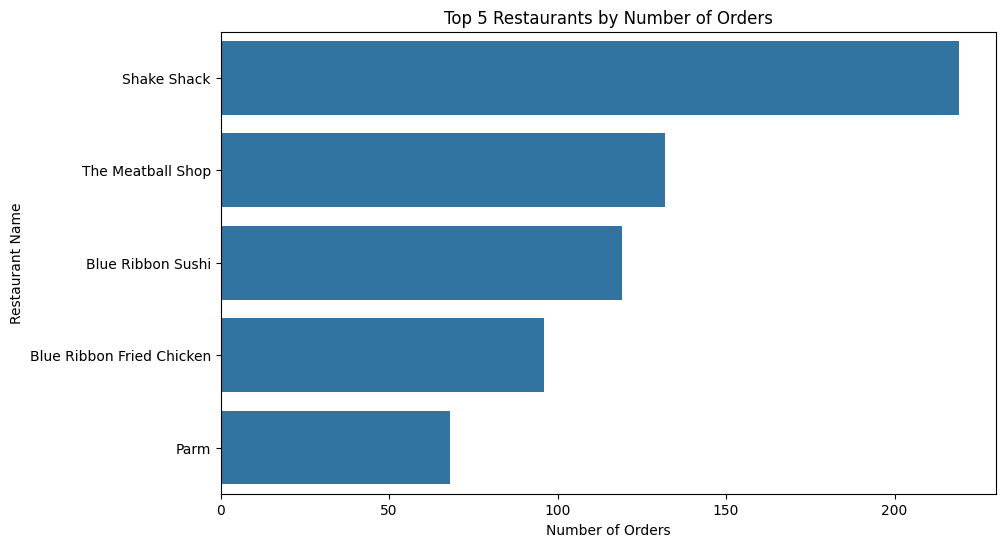

In [53]:
# Plot the top 5 restaurants by their number of orders
plt.figure(figsize=(10, 6))
sns.barplot(x=top_5_restaurants.values, y=top_5_restaurants.index)
plt.title('Top 5 Restaurants by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.show()

#### Observations:

The top 5 restaurants by number of orders are Shake Shack, The Meatball Shop, Blue Ribbon Sushi, Blue Ribbon Fried Chicken, and Parm.

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [54]:
# Check cuisine type counts for day of the week as weekend
df.loc[df['day_of_the_week']=='Weekend', 'cuisine_type'].value_counts()

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Middle Eastern,32
Mediterranean,32
Thai,15


#### Observations:

American is the top cuisine ordered on the weekends, followed by Japanese and Italian.

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [55]:
# Calculate percentage of high value orders that cost greater than 20 dollars
high_value_orders = len(df[df['cost_of_the_order'] > 20])
total_orders = len(df)

print("High-value orders %:", high_value_orders / total_orders)

High-value orders %: 0.2924130663856691


#### Observations:

The percentage of orders that cost more than 20 dollars is approximately 29.24%.

### **Question 10**: What is the mean order delivery time? [1 mark]

In [56]:
mean_delivery_time = df['delivery_time'].mean()
print(f"Mean order delivery time: {mean_delivery_time:.2f} minutes")

Mean order delivery time: 24.16 minutes


#### Observations:

The mean order delivery time is approximately 24.16 minutes.

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [57]:
# Count number of orders per customer
top_3_customers = (
    df['customer_id']
    .value_counts()   # count occurrences
    .head(3)          # top 3
    .reset_index()    # convert to DataFrame
)

# Rename columns for clarity
top_3_customers.columns = ['customer_id', 'order_count']
print(top_3_customers, '\n')

   customer_id  order_count
0        52832           13
1        47440           10
2        83287            9 



#### Observations:

The top three most frequently ordering customers are:
1. Customer 52832 with 13 orders.
2. Customer 47440 with 10 orders.
3. Customer 83287 with 9 orders.

### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


In [58]:
# Convert rating value of "Not given" to NaN and rating column to float
df["rating"] = df["rating"].replace('Not given', np.nan).astype(float)
df["rating"]

,rating
0,NaN
1,NaN
2,5.0
3,3.0
4,4.0
...,...
1893,5.0
1894,5.0
1895,NaN
1896,5.0


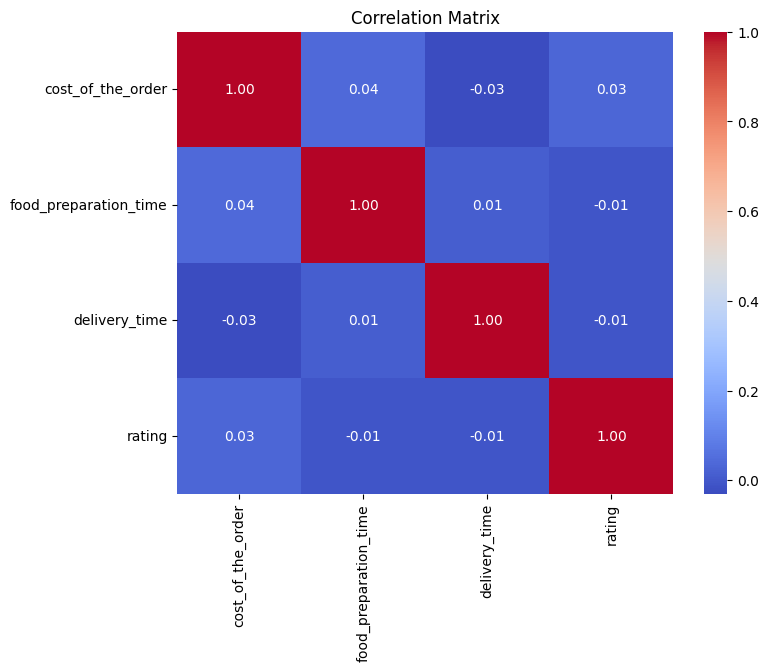

In [59]:
# Select numerical columns for correlation analysis
num_cols = ['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating']

# Compute correlation matrix
corr = df[num_cols].corr()

# Plot heatmap to visualize relationships
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")

# Add title for clarity
plt.title('Correlation Matrix')

# Display plot
plt.show()

The above correlation heatmap shows very weak relationships between the variables cost_of_the_order, food_preparation_time, delivery_time, and rating.

All correlation coefficients are close to zero, indicating that these variables do not exhibit direct linear dependencies.

Notably, delivery time and rating show negligible correlation, suggesting that customer satisfaction is not linearly influenced by delivery duration.

Similarly, food preparation time and delivery time appear largely independent, indicating that kitchen operations and delivery logistics function separately.

There are essentially NO linear relationships between any of these variables.

Cost does not meaningfully relate to rating.
Delivery time does not linearly relate to rating.
Prep time does not strongly influence delivery time.

These findings imply that customer satisfaction is likely driven by more complex, non-linear relationships or threshold effects rather than simple linear trends.

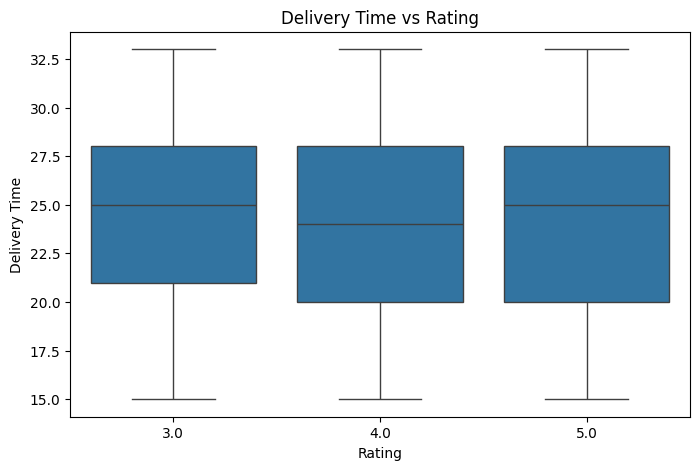

In [60]:
# Create boxplot to compare delivery time across rating levels
plt.figure(figsize=(8, 5))
sns.boxplot(
    x='rating',        # Rating categories on x-axis
    y='delivery_time', # Delivery time on y-axis
    data=df
)

# Add labels and title
plt.title('Delivery Time vs Rating')
plt.xlabel('Rating')
plt.ylabel('Delivery Time')

# Display plot
plt.show()

The boxplot above shows the delivery time versus rating, in which we can see that the three distributions heavily overlap. All three ratings share roughly an interquartile range of about 20–28 min and a range of about 15–33 min.

This suggests that delivery time is not a strong differentiator of rating in this dataset, further validating that there is no meaningful relationship or pattern between the two variables.

If delivery time mattered strongly toward ratings, we could expect, for example, lower delivery times to mean higher ratings, or conversely higher delivery times to mean lower ratings. We do not see any of that here.

This dataset may suggest that users have a certain window of tolerance, meaning if delivery time is between about 15–30 min, all customers are equally satisfied. No real penalty, unless it's extremely slow, instances of which we do not find in this dataset.

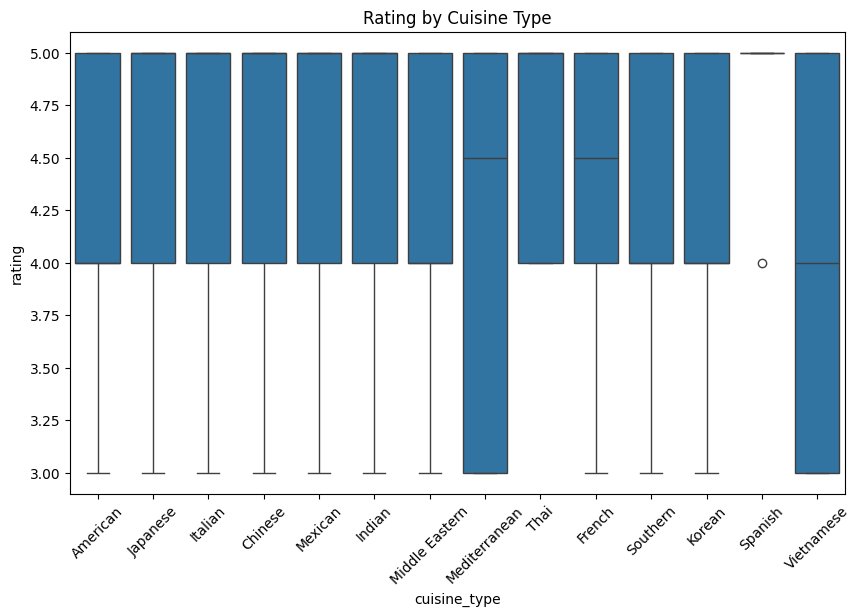

In [61]:
# Create boxplot to compare ratings across cuisine types
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='cuisine_type', # Cuisine categories on x-axis
    y='rating',       # Customer ratings on y-axis
    order=df['cuisine_type'].value_counts().index # Order by cuisine counts
)

# Rotate labels for readability
plt.xticks(rotation=45)

# Add title
plt.title('Rating by Cuisine Type')

# Display plot
plt.show()

The boxplot above shows that ratings are consistently high (4-5) across all cuisines. Mediterranean and Vietnamese cuisines do show slightly more spread towards a 3 rating, however still not meaningfully different from others.

There are very limited low ratings, with no 1 or 2 ratings. Because of this weak negative signal, it may be hard to distinguish performance differences.

The dataset shows that cuisine type does NOT strongly influence rating, and does not provide enough variation to distinguish them.

People may only be rating their orders when they are satisfied, giving a high bias (ratings of 4-5), and may not be rating when they are not satisfied (ratings of Not given, or 1-3).

In [62]:
df.groupby('cuisine_type')['rating'].agg(['mean', 'count'])

,mean,count
cuisine_type,,
American,4.298913,368
Chinese,4.338346,133
French,4.300000,10
Indian,4.540000,50
Italian,4.360465,172
Japanese,4.373626,273
Korean,4.111111,9
Mediterranean,4.218750,32
Mexican,4.416667,48


The above code shows that Spanish cuisine is, on average, rated the highest, with an average rating of approximately 4.83. However, with only 6 orders, it is not truly meaningful to say that Spanish cuisine is the tastiest in this dataset. With an average rating of about 4.3 and the most orders of 368, American cuisine still dominates in popularity.

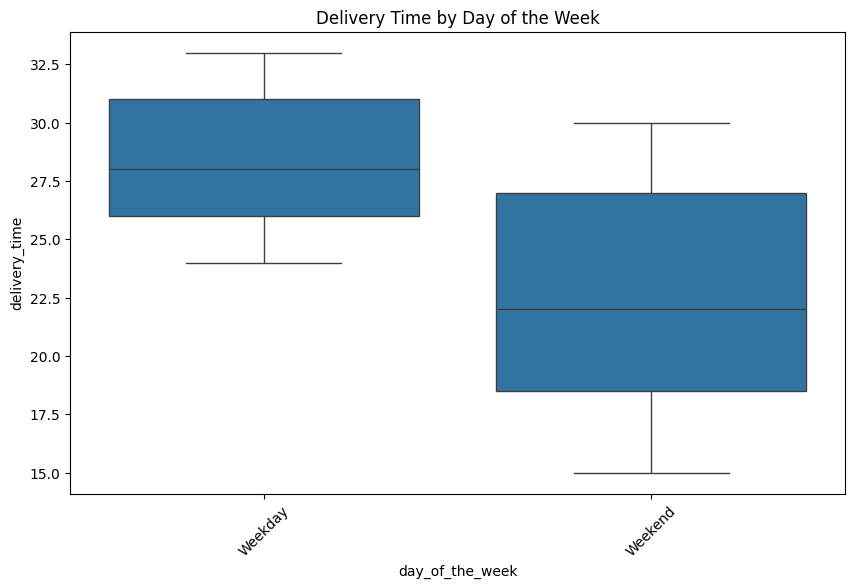

In [63]:
# Create boxplot to compare delivery time across days
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='day_of_the_week',
    y='delivery_time',
    order=['Weekday', 'Weekend']
)

# Rotate labels for readability
plt.xticks(rotation=45)

# Add title
plt.title('Delivery Time by Day of the Week')

# Display plot
plt.show()

The above boxplot shows that weekdays have higher delivery times, the weekday median being about 28 minutes, and the weekend median about 22 minutes.

Weekdays show to be more consistently slow with delivery times, with the weekday interquartile range about 26–31 minutes (tight but high), and the weekend interquartile range about 18–27 min (lower and wider).

The weekend shows a higher spread/range of delivery times, suggesting that some deliveries are very quick and some much slower (more variability in delivery performance on the weekends).

Higher weekday delivery times could likely be due to higher traffic. Lower weekend delivery times could possibly be due to gig workers who prefer weekend hours.

In [64]:
df.groupby('day_of_the_week')['delivery_time'].mean()

,delivery_time
day_of_the_week,
Weekday,28.340037
Weekend,22.470022


In [65]:
df['day_of_the_week'].value_counts()

,count
day_of_the_week,
Weekend,1351
Weekday,547


The above code shows that even with almost 2.5 times the amount of orders on the weekends than on the weekdays, delivery times are still on average lower on the weekends.

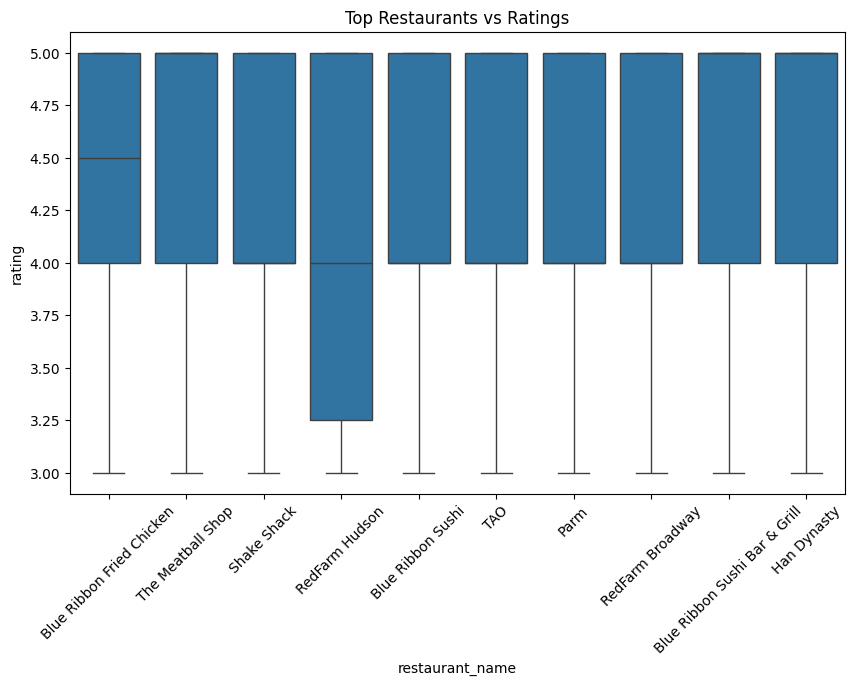

In [66]:
# Identify top 10 restaurants by number of orders
top_restaurants = df['restaurant_name'].value_counts().head(10).index

# Filter dataset to include only top restaurants
filtered = df[df['restaurant_name'].isin(top_restaurants)]

# Create boxplot to compare ratings across top restaurants
plt.figure(figsize=(10, 6))
sns.boxplot(data=filtered, x='restaurant_name', y='rating')

# Rotate labels for readability
plt.xticks(rotation=45)

# Add title
plt.title('Top Restaurants vs Ratings')

# Display plot
plt.show()

The above boxplot further reinforces how little rating is affected by other variables (refer to heatmap in the beginning). We cannot see much of any meaningful interpretation with the limited rating signals this dataset has. The plot shows that the top ten restaurants are more or less have interquartile ranges of high 4-5 ratings.

We can at least deduce that RedFarm Hudson has more lower ratings than any of the other top ten restaurants.

In [67]:
# Compare average metrics between ratings
df.groupby('rating')[
    ['delivery_time', 'food_preparation_time', 'cost_of_the_order']
].mean()

,delivery_time,food_preparation_time,cost_of_the_order
rating,,,
3.0,24.558511,27.430851,16.223351
4.0,23.867876,27.396373,16.710337
5.0,24.212585,27.355442,16.965697


The above code further displays how little the rating is affected by other quantitative variables. The average values per column are very similar between all three ratings.

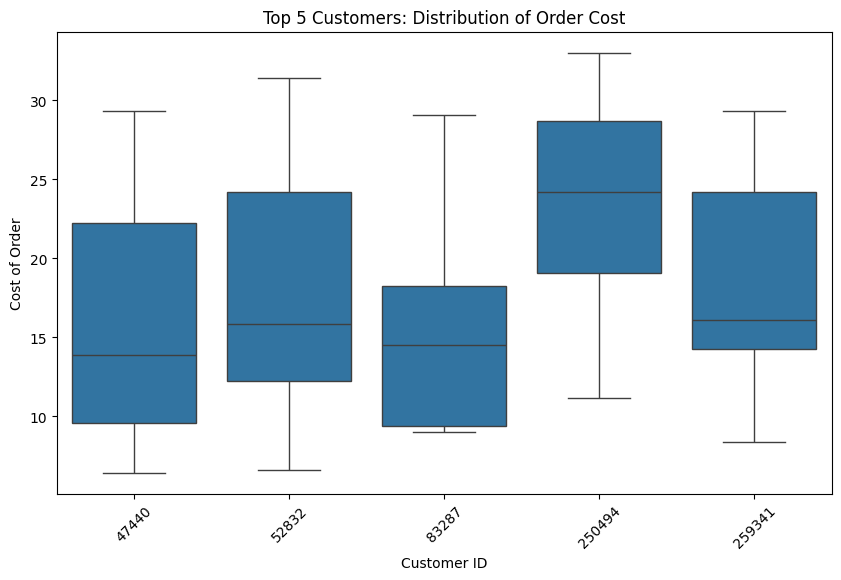

In [68]:
# Find top 5 customers by number of orders
top_customers = df['customer_id'].value_counts().head(5).index

# Filter dataset to only include those customers
top_df = df[df['customer_id'].isin(top_customers)]

# Create boxplot to show distribution of order costs per customer
plt.figure(figsize=(10,6))
sns.boxplot(
    data=top_df,
    x='customer_id',      # each customer on x-axis
    y='cost_of_the_order' # order cost on y-axis
)

# Add labels and title
plt.title('Top 5 Customers: Distribution of Order Cost')
plt.xlabel('Customer ID')
plt.ylabel('Cost of Order')

# Rotate x labels for clarity
plt.xticks(rotation=45)

# Display plot
plt.show()

The above boxplot shows us the top 5 customers and their spending behavior. We can conclude that:
1. Customer 250494 is the highest spender, with a median of about 25 dollars and upper range going above 30 dollars. This customer consistently places higher-value orders.
2. Customers 52832 and 259341 are moderate spenders, with medians around 16 dollars and a slightly wider spread than 250494, suggesting that they place a mix of low, medium, and occasional high cost orders.
3. Customers 47440 and 83287 are lower spenders, with medians around 14-15 dollars. Customer 83287 has the narrowest interquartile range, suggesting that they consistently spend lower on their orders.

Overall, we can deduce that the top customers are not all "high spenders", but rather they differ in how they spend.

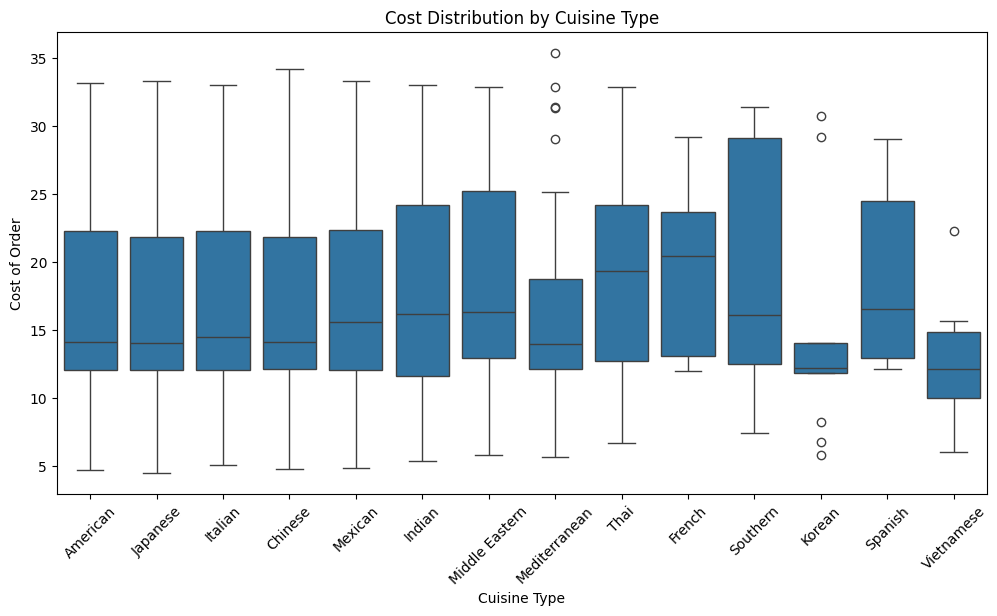

In [69]:
# Order cuisines by frequency for cleaner visualization
cuisine_order = df['cuisine_type'].value_counts().index

# Create the boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='cuisine_type',      # cuisine categories on x-axis
    y='cost_of_the_order', # order cost on y-axis
    order=cuisine_order    # sort by popularity
)

# Add labels and title
plt.title('Cost Distribution by Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Cost of Order')

# Rotate x-axis labels for better visibility
plt.xticks(rotation=45)

# Display plot
plt.show()

The above boxplot shows:
1. Cuisines that tend to be more expensive on average include French (about 20–21 dollars median), Thai (about 19–20 dollars median), and Spanish (about 16–17 dollars median, but higher upper range).
2. Mid-range cuisines include Indian, Middle Eastern, and Mexican (about 15–17 dollars median).
3. The most affordable or budget-friendly options seem to be Korean and Vietnamese (about 12–13 dollars median).

There is overlap between cuisines and their interquartile ranges, most of which fall between about 12 to 22 dollars.

Southern cuisine displays the largest interquartile range, suggesting it may have the highest variability in cheap and premium items on their menus.

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [70]:
# Group data by restaurant and aggregate mean and counts of ratings
restaurant_ratings = df.groupby('restaurant_name')['rating'].agg(['mean', 'count'])

# Find restaurants that fulfill the criteria described
eligible_restaurants = restaurant_ratings[
    (restaurant_ratings['count'] > 50) & (restaurant_ratings['mean'] > 4)
]

# Print result
print(eligible_restaurants)

                               mean  count
restaurant_name                           
Blue Ribbon Fried Chicken  4.328125     64
Blue Ribbon Sushi          4.219178     73
Shake Shack                4.278195    133
The Meatball Shop          4.511905     84


#### Observations:

Restaurants that are eligible to get the promotional offer are:
1. Blue Ribbon Fried Chicken
2. Blue Ribbon Sushi
3. Shake Shack
4. The Meatball Shop


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [71]:
# Define a function to calculate commission per order
def calculate_revenue(cost):
    if cost > 20:
        return cost * 0.25   # 25% commission
    elif cost > 5:
        return cost * 0.15   # 15% commission
    else:
        return 0             # no commission

# Apply the function to create a new column
df['revenue'] = df['cost_of_the_order'].apply(calculate_revenue)

# Sum total revenue
total_revenue = df['revenue'].sum()

# Print result
print("Total Revenue:", total_revenue)

Total Revenue: 6166.303


#### Observations:

The net revenue generated by the company for hosting these restaurants on their FoodHub platform is about 6166.30 dollars.

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [72]:
# Create total time column
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

# Count orders where total time > 60 minutes
orders_over_60 = (df['total_time'] > 60).sum()

# Total number of orders
total_orders = len(df)

# Calculate percentage
percentage_over_60 = (orders_over_60 / total_orders) * 100

# Print result
print("Percentage of orders > 60 minutes:", percentage_over_60)

Percentage of orders > 60 minutes: 10.537407797681771


#### Observations:

Approximately 10.54% of orders take more than 60 minutes to get delivered from the time the order is placed.

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [73]:
# Group data by day of week and calculate the mean delivery times
mean_delivery_times = df.groupby('day_of_the_week')['delivery_time'].mean()

# Print result
print(mean_delivery_times)

day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


#### Observations:

The mean delivery time for weekdays is about 28.34 minutes and for weekends is about 22.47 minutes. It is higher in the weekdays than on the weekends. This could be due to staff shortages, routing issues, or traffic during the weekdays that is not seen on the weekends.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:

* Customer ratings are not a strong differentiator in this dataset and provide limited signal for identifying problems. Ratings are heavily concentrated between 4–5, with many "Not given" and a lack of 1-2 ratings, creating a high bias or ceiling effect.

* Customers appear to have a tolerance window for delivery time, within which satisfaction (rating) remains unaffected. Correlation between delivery time and rating is negligible (about 0). Boxplots show no meaningful difference across rating levels. Most delivery times fall within a range that may suggest "tolerance" for customers.

* Kitchen operations and delivery logistics function as separate systems (they are independent), and delays are not compounded. Correlation between preparation time and delivery time is negligible (about 0). Heatmap and scatterplot shows no relationship.

* Operational efficiency is higher on weekends. Delivery performance shows to be better on the weekends. Weekend median delivery time is lower than weekdays. Weekdays are slower and more consistent.

* Cuisine type may influence cost, but not customer satisfaction (rating). There are clear differences in cost distribution by cuisine. There are no meaningful differences in ratings across cuisines.

* Customer behavior varies among the top users of FoodHub. Some customers may order frequently but spend less per order, and others may order frequently and spend more. Customers segment into different revenue profiles and spending behaviors.

* Revenue is driven by higher costing orders (refer back to question 14). Orders greater than 20 dollars generate higher commission (25%). Lower-cost orders contribute less per transaction. This suggests that business revenue is disproportionately influenced by higher-value orders

### Recommendations:

* Improve the rating system's sensitivity. The problem is that ratings are too compressed (mostly 4–5), with many not given and a lack of low identifying ratings (1-2), making it difficult to identify underperforming areas. The business should introduce more granular feedback (like on delivery, food quality, packaging), introduce optional written feedback prompts, and encourage ratings for all orders. This could enrich the data, which in turn will allow better decision-making.

* Optimize weekday delivery operations. The problem is that weekday deliveries are slower than on the weekends. The business should increase driver availability during weekdays, analyze weekday routing/logistics inefficiencies, and introduce weekday incentives for delivery partners and gig workers. Reduced delivery times could mean improved consistency and scalability.

* Put focus on increasing high-value orders. The observation is that revenue depends heavily on higher-cost orders. The business should promote combo meals and bundles, promote upselling (add-ons, drinks, sides, etc.), and highlight premium menu items. A higher average order value could mean increased revenue per order.

* Segment and target customers differently. The observation is that customers behave differently. Some are high-frequency, low-spend, while others are high-spend. The business should segment their customers into multiple groups, such as high-frequency-low-spend (A) and low-frequency-high-spend (B). For group A, provide upsell offers to promote revenue. For group B, provide loyalty rewards to promote purchasing again. This could increase the lifetime value per customer as well as customer retention.

* Leverage cuisine-based pricing strategies. The observation is that some cuisines naturally support higher pricing. The business should promote higher-margin cuisines (like French and Thai), partner more with premium restaurants, and position certain cuisines as “premium experiences”. This could improve margins without increasing volume.

* Reduce variability in high-variance cuisines. The observation is that some cuisines, like Southern and Mediterranean, show high cost variability. The business should standardize pricing ranges, improve menu clarity, and identify outlier pricing. This could result in more predictable customer expectations.

* Monitor orders near 60 minute threshold. The problem is long wait times (prep + delivery) can impact customer experience beyond tolerance. The business should track the percentage of orders that take more than 60 minutes for prep and delivery, set SLA targets, and prioritize intervention for delayed orders (understand why). This could prevent negative customer experiences due to wait times before they happen.

---